# Submission 2 &ndash; Intermediate Submission

## Instructions

- Fill out the *Basic Information* and the *Results* sections.
- Make sure that this `.ipynb` file displays correctly in the GitHub file preview, including any visual output.
- If you find that any output does not display correctly, include a static screenshot as an image. For interactive outputs, add a link to a short screencast located in your repository.
- Push all required files before the deadline.

---
## Basic Information

**Team Name:** Grafica

**Team Members:**
- Amr Abdullah
- Mihajlo Živić
- Marlon Orta
- Mohammad Shadik Ansari

**Dataset Description:**  
(max. 75 words; this serves just as a reminder)

`Global Suicide Rates (1985–2016)` from `Kaggle`. Contains about 27,820 records of annual suicide counts, rates per 100k population, and socioeconomic indicators (GDP, HDI) across 195 countries and territories. Key dimensions: year, country, age group, sex, and suicides per 100k population."

---

## Code

Here you may place any code that is not an immediate part of your submission. Only the content of the *Results* sections will be graded for this submission.

### 1. Imports

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pycountry_convert as pc

# Display and plotting defaults
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100


### 2. Data loading

We download the dataset directly from Kaggle via `kagglehub` so the notebook is reproducible without manual file placement.

In [2]:
import kagglehub

path = kagglehub.dataset_download("russellyates88/suicide-rates-overview-1985-to-2016")
print("Path to dataset files:", path)

csv_file = os.path.join(path, "master.csv")
df_raw = pd.read_csv(csv_file)
print(f"Loaded: {df_raw.shape[0]:,} rows * {df_raw.shape[1]} columns")
df_raw.head()


Path to dataset files: /Users/amrabdullah/.cache/kagglehub/datasets/russellyates88/suicide-rates-overview-1985-to-2016/versions/1
Loaded: 27,820 rows * 12 columns


,country,year,sex,age,suicides_no,population,suicides/100k pop,country-year,HDI for year,gdp_for_year ($),gdp_per_capita ($),generation
0,Albania,1987,male,15-24 years,21,312900,6.71,Albania1987,NaN,"2,156,624,900",796,Generation X
1,Albania,1987,male,35-54 years,16,308000,5.19,Albania1987,NaN,"2,156,624,900",796,Silent
2,Albania,1987,female,15-24 years,14,289700,4.83,Albania1987,NaN,"2,156,624,900",796,Generation X
3,Albania,1987,male,75+ years,1,21800,4.59,Albania1987,NaN,"2,156,624,900",796,G.I. Generation
4,Albania,1987,male,25-34 years,9,274300,3.28,Albania1987,NaN,"2,156,624,900",796,Boomers


### 3. Initial exploration

Quick look at column names (some have inconsistent spacing), data types, missing values, and basic coverage.

In [3]:
print("Original columns (note inconsistent naming):")
for c in df_raw.columns:
    print(f"  {repr(c)}")

print("\nDtypes:")
print(df_raw.dtypes)

print("\nMissing values per column:")
print(df_raw.isna().sum())

print(f"\nYear range:    {df_raw['year'].min()} - {df_raw['year'].max()}")
print(f"Countries:      {df_raw['country'].nunique()}")
print(f"Total records:  {len(df_raw):,}")


Original columns (note inconsistent naming):
  'country'
  'year'
  'sex'
  'age'
  'suicides_no'
  'population'
  'suicides/100k pop'
  'country-year'
  'HDI for year'
  ' gdp_for_year ($) '
  'gdp_per_capita ($)'
  'generation'

Dtypes:
country                   str
year                    int64
sex                       str
age                       str
suicides_no             int64
population              int64
suicides/100k pop     float64
country-year              str
HDI for year          float64
 gdp_for_year ($)         str
gdp_per_capita ($)      int64
generation                str
dtype: object

Missing values per column:
country                   0
year                      0
sex                       0
age                       0
suicides_no               0
population                0
suicides/100k pop         0
country-year              0
HDI for year          19456
 gdp_for_year ($)         0
gdp_per_capita ($)        0
generation                0
dtype: int64

Year rang

### 4. Standardise column names

Rename columns to snake_case and convert `gdp_for_year` from a comma-separated string to a numeric type.

In [4]:
df = df_raw.copy()

df = df.rename(columns={
    "suicides/100k pop":     "suicides_per_100k",
    "country-year":          "country_year",
    "HDI for year":          "hdi_for_year",
    " gdp_for_year ($) ":    "gdp_for_year",
    "gdp_per_capita ($)":    "gdp_per_capita",
})

# gdp_for_year is stored like "2,156,624,900" -> convert to numeric
df["gdp_for_year"] = (
    df["gdp_for_year"].astype(str).str.replace(",", "", regex=False).astype(float)
)

print("Renamed columns:")
print(df.columns.tolist())
df.head(3)


Renamed columns:
['country', 'year', 'sex', 'age', 'suicides_no', 'population', 'suicides_per_100k', 'country_year', 'hdi_for_year', 'gdp_for_year', 'gdp_per_capita', 'generation']


,country,year,sex,age,suicides_no,population,suicides_per_100k,country_year,hdi_for_year,gdp_for_year,gdp_per_capita,generation
0,Albania,1987,male,15-24 years,21,312900,6.71,Albania1987,NaN,2.156625e+09,796,Generation X
1,Albania,1987,male,35-54 years,16,308000,5.19,Albania1987,NaN,2.156625e+09,796,Silent
2,Albania,1987,female,15-24 years,14,289700,4.83,Albania1987,NaN,2.156625e+09,796,Generation X


### 5. Drop sparse and redundant columns

- **HDI for year** is missing in ~70% of rows, we dropt it
- **country_year** is just `country + year` concatenated; its redundant, we drop it. 
- **2016** records are incomplete -only a handful of countries reported- so we drop this year.
- **generation** can be easily devrived from `age` + `year` and isn't used by any of our hypotheses, so we also drop it/

In [5]:
# Inspect HDI sparsity before removal
hdi_missing_pct = df["hdi_for_year"].isna().mean() * 100
print(f"HDI missing: {hdi_missing_pct:.1f}%")

df = df.drop(columns=["hdi_for_year", "country_year", "generation"])

# Drop incomplete 2016
n_2016 = (df["year"] == 2016).sum()
print(f"2016 rows dropped: {n_2016:,}")
df = df[df["year"] != 2016].copy()

print(f"After drops: {df.shape[0]:,} rows x {df.shape[1]} columns")


HDI missing: 69.9%
2016 rows dropped: 160
After drops: 27,660 rows x 9 columns


### 6. Filter countries with insufficient history

Some countries report only one or two years of data (too little to support trend analysis or fair country level comparisons). We keep only countries with **more than 3 years** of records.

In [6]:
years_per_country = df.groupby("country")["year"].nunique()

dropped = years_per_country[years_per_country <= 3].sort_values()
keep = years_per_country[years_per_country > 3].index

print(f"Dropping {len(dropped)} countries with <=3 years of data:")
for c, n in dropped.items():
    print(f"  {c}: {n} year(s)")

df = df[df["country"].isin(keep)].copy()
print(f"\nRemaining: {df['country'].nunique()} countries, {df.shape[0]:,} rows")


Dropping 7 countries with <=3 years of data:
  Cabo Verde: 1 year(s)
  Dominica: 1 year(s)
  Macau: 1 year(s)
  Bosnia and Herzegovina: 2 year(s)
  Oman: 3 year(s)
  Saint Kitts and Nevis: 3 year(s)
  San Marino: 3 year(s)

Remaining: 93 countries, 27,492 rows


### 7. Add continent column

We attach a `continent` field via `pycountry_convert`, with manual overrides for country names the library doesn't recognise out of the box.

In [7]:
# Names that are not directly recognised by pycountry_convert
manual_continent = {
    "Republic of Korea":              "Asia",
    "Saint Vincent and Grenadines":   "North America",
    "Russian Federation":             "Europe",
    "Macau":                          "Asia",
    "Cabo Verde":                     "Africa",
    "Czech Republic":                 "Europe",
}


def country_to_continent(name: str) -> str:
    if name in manual_continent:
        return manual_continent[name]
    try:
        code_alpha2 = pc.country_name_to_country_alpha2(name)
        cont_code = pc.country_alpha2_to_continent_code(code_alpha2)
        return pc.convert_continent_code_to_continent_name(cont_code)
    except Exception:
        return "Unknown"


df["continent"] = df["country"].apply(country_to_continent)

print("Continent distribution (rows):")
print(df["continent"].value_counts())

unknown = df.loc[df["continent"] == "Unknown", "country"].unique()
if len(unknown):
    print(f"\nStill unmapped (add to manual_continent): {list(unknown)}")
else:
    print("\nAll countries mapped successfully.")


Continent distribution (rows):
continent
Europe           11268
North America     6000
Asia              5268
South America     3156
Oceania            972
Africa             828
Name: count, dtype: int64

All countries mapped successfully.


### 8. Feature engineering

- **`decade`** — derived from `year`, used in our ypothesis A.2.
- **`age`** — convert to an ordered categorical so plots show   age groups in a meaningful sequence rather than alphabetical order.
- **`sex`** — convert to categorical for cleaner grouping and plotting.

In [8]:
# Decade (exmaple 1995 -> 1990)
df["decade"] = (df["year"] // 10) * 10

# Ordered age categories
age_order = [
    "5-14 years",
    "15-24 years",
    "25-34 years",
    "35-54 years",
    "55-74 years",
    "75+ years",
]
df["age"] = pd.Categorical(df["age"], categories=age_order, ordered=True)

# Sex as categorical
df["sex"] = df["sex"].astype("category")

print(df.dtypes)


country                   str
year                    int64
sex                  category
age                  category
suicides_no             int64
population              int64
suicides_per_100k     float64
gdp_for_year          float64
gdp_per_capita          int64
continent                 str
decade                  int64
dtype: object


### 9. Helper function: `rate_per_100k`

whenever we aggregate the data we compute the rate as `sum(suicides_no) / sum(population) * 100,000`. this is a **population-weighted** rate; simply averaging the row level `suicides_per_100k` would over weight small subgroups. Defining this once and reusing it keeps every visualization consistent.

In [9]:
def rate_per_100k(data: pd.DataFrame, group_cols) -> pd.DataFrame:
    """Population-weighted suicide rate per 100k for the given grouping."""
    if isinstance(group_cols, str):
        group_cols = [group_cols]
    g = (
        data.groupby(group_cols, observed=True)
            .agg(suicides_no=("suicides_no", "sum"),
                 population=("population", "sum"))
            .reset_index()
    )
    g["suicides_per_100k"] = g["suicides_no"] / g["population"] * 1e5
    return g


### 10. Final sanity checks

Confirm the cleaned frame is in good shape and that the helper function returns sensible numbers.

In [10]:
print("Final cleaned dataset")
print("=" * 40)
print(f"Rows:        {df.shape[0]:,}")
print(f"Columns:     {df.shape[1]}  -> {df.columns.tolist()}")
print(f"Years:       {df['year'].min()} - {df['year'].max()}")
print(f"Countries:   {df['country'].nunique()}")
print(f"Continents:  {sorted(df['continent'].unique())}")
print(f"Missing:     {df.isna().sum().sum()}")

print("\nGlobal rate per 100k by sex (sanity):")
print(rate_per_100k(df, "sex").to_string(index=False))

print("\nGlobal rate per 100k by decade (sanity):")
print(rate_per_100k(df, "decade").to_string(index=False))


Final cleaned dataset
Rows:        27,492
Columns:     11  -> ['country', 'year', 'sex', 'age', 'suicides_no', 'population', 'suicides_per_100k', 'gdp_for_year', 'gdp_per_capita', 'continent', 'decade']
Years:       1985 - 2015
Countries:   93
Continents:  ['Africa', 'Asia', 'Europe', 'North America', 'Oceania', 'South America']
Missing:     0

Global rate per 100k by sex (sanity):
   sex  suicides_no  population  suicides_per_100k
female      1555919 26197785175           5.939124
  male      5176474 24974895551          20.726709

Global rate per 100k by decade (sanity):
 decade  suicides_no  population  suicides_per_100k
   1980       644845  5413081796          11.912715
   1990      2293177 16063187713          14.275977
   2000      2439582 18230221715          13.382075
   2010      1354789 11466189502          11.815512


---
## Results &ndash; Simple Hypotheses/Tasks

### A.1

Restate your hypothesis/task below.

**Hypothesis A.1:** Suicide rates differ significantly between males and females: a direct comparison of the population-weighted suicide rate per 100,000 between males and females globally across the full 1985–2015 dataset.

Place your visualizations below (max. 2). Make sure that everyting displays correctly in the GitHub file preview.

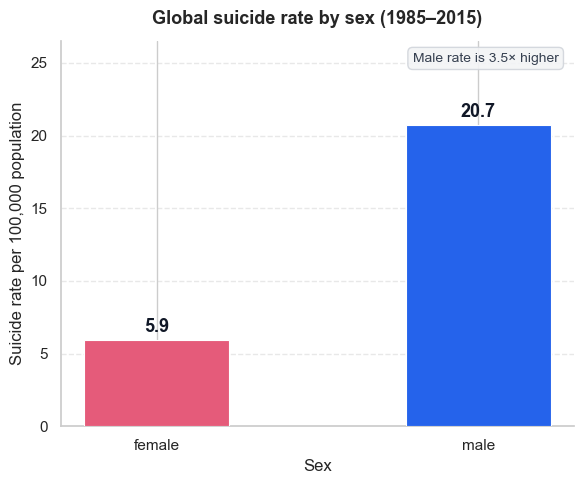

Male: 20.73 | Female: 5.94 | Ratio: 3.49x


In [11]:
# A.1: Male vs Female global suicide rate — bar chart 
# Population weighted rate by sex -all years, all countries-
sex_rates = rate_per_100k(df, "sex").sort_values("sex")

fig, ax = plt.subplots(figsize=(6, 5))

COLORS = {"male": "#2563EB", "female": "#E55B7A"}
bars = ax.bar(
    sex_rates["sex"],
    sex_rates["suicides_per_100k"],
    color=[COLORS[s] for s in sex_rates["sex"]],
    width=0.45,
    edgecolor="white",
    linewidth=0.8,
    zorder=3,
)

# Value labels on top of each bar
for bar, val in zip(bars, sex_rates["suicides_per_100k"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.25,
        f"{val:.1f}",
        ha="center", va="bottom", fontsize=13, fontweight="bold",
        color="#111827",
    )

# Male to female ratio callout
male_rate   = sex_rates.loc[sex_rates["sex"] == "male",   "suicides_per_100k"].values[0]
female_rate = sex_rates.loc[sex_rates["sex"] == "female", "suicides_per_100k"].values[0]
ratio = male_rate / female_rate
ax.text(
    0.97, 0.97,
    f"Male rate is {ratio:.1f}\u00d7 higher",
    transform=ax.transAxes, ha="right", va="top",
    fontsize=10, color="#374151",
    bbox=dict(boxstyle="round,pad=0.35", facecolor="#F3F4F6",
              edgecolor="#D1D5DB", alpha=0.9),
)

ax.set_xlabel("Sex", fontsize=12)
ax.set_ylabel("Suicide rate per 100,000 population", fontsize=12)
ax.set_title("Global suicide rate by sex (1985\u20132015)", fontsize=13,
             fontweight="bold", pad=12)
ax.set_ylim(0, male_rate * 1.28)
ax.yaxis.grid(True, linestyle="--", alpha=0.45, zorder=0)
ax.set_axisbelow(True)
sns.despine(ax=ax)

plt.tight_layout()
plt.savefig("a1_sex_bar.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Male: {male_rate:.2f} | Female: {female_rate:.2f} | Ratio: {ratio:.2f}x")


Describe your visualizations and findings. Be clear which chart(s) you are referring to and relate your findings to the hypothesis/task.
Use no more than 150 words and indicate the word count of your description below.

**Description:** The bar chart displays the population weighted global suicide rate per 100,000 for males and females, aggregated across all countries and years from 1985 to 2015. Males show a substantially higher rate wiht roughly 3 or 4 times than of females. This large and consistent disparity confirms Hypothesis A.1: suicide rates differ significantly by sex, with males at substantially greater risk. A bar chart on a shared axis was chosen because position is the most accurate encoding channel for comparing two group magnitudes according to Munzner.

**Word count**: 86

### A.2

Restate your hypothesis/task below.

**Hypothesis A.2:** More suicides occurred during the 1990s: the global population-weighted suicide rate per 100,000 reached its highest point during the decade 1990 rather than in any other decade covered by the dataset.

Place your visualizations below (max. 2). Make sure that everyting displays correctly in the GitHub file preview.

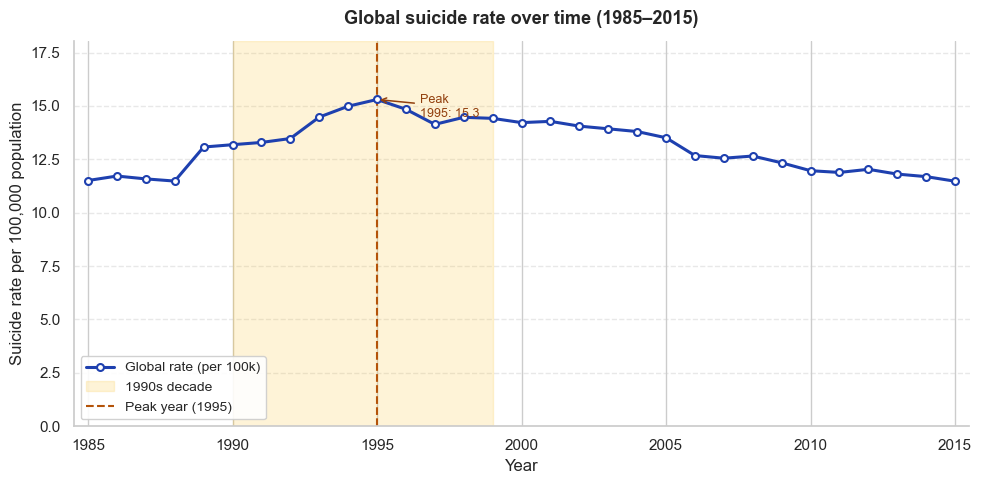

1985 rate: 11.51 | Peak (1995): 15.30 | 2015: 11.47


In [12]:
# A.2: Global suicide rate over time with 1990s highlighted — line chart ─
year_rates = rate_per_100k(df, "year").sort_values("year")

fig, ax = plt.subplots(figsize=(10, 5))

# Main trend line
ax.plot(
    year_rates["year"], year_rates["suicides_per_100k"],
    color="#1E40AF", linewidth=2.2,
    marker="o", markersize=5,
    markerfacecolor="white", markeredgecolor="#1E40AF", markeredgewidth=1.5,
    zorder=3, label="Global rate (per 100k)",
)

# Shade the 1990s decade
ax.axvspan(1990, 1999, color="#FBBF24", alpha=0.18, zorder=1, label="1990s decade")

# Mark the peak year
peak_row  = year_rates.loc[year_rates["suicides_per_100k"].idxmax()]
peak_year = int(peak_row["year"])
peak_val  = peak_row["suicides_per_100k"]

ax.axvline(peak_year, color="#B45309", linestyle="--", linewidth=1.5, zorder=2,
           label=f"Peak year ({peak_year})")
ax.annotate(
    f"Peak\n{peak_year}: {peak_val:.1f}",
    xy=(peak_year, peak_val),
    xytext=(peak_year + 1.5, peak_val - 0.8),
    fontsize=9, color="#92400E",
    arrowprops=dict(arrowstyle="->", color="#92400E", lw=1.1),
)

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Suicide rate per 100,000 population", fontsize=12)
ax.set_title("Global suicide rate over time (1985\u20132015)", fontsize=13,
             fontweight="bold", pad=12)
ax.set_xlim(year_rates["year"].min() - 0.5, year_rates["year"].max() + 0.5)
ax.set_ylim(0, peak_val * 1.18)
ax.xaxis.set_major_locator(mticker.MultipleLocator(5))
ax.yaxis.grid(True, linestyle="--", alpha=0.45, zorder=0)
ax.set_axisbelow(True)
ax.legend(loc="lower left", fontsize=10, framealpha=0.9)
sns.despine(ax=ax)

plt.tight_layout()
plt.savefig("a2_time_line.png", dpi=150, bbox_inches="tight")
plt.show()

first_val = year_rates["suicides_per_100k"].iloc[0]
last_val  = year_rates["suicides_per_100k"].iloc[-1]
print(f"1985 rate: {first_val:.2f} | Peak ({peak_year}): {peak_val:.2f} | 2015: {last_val:.2f}")


Describe your visualizations and findings. Be clear which chart(s) you are referring to and relate your findings to the hypothesis/task. Use no more than 150 words and indicate the word count of your description below.

**Description:** The line chart tracks the population weighted global suicide rate per 100,000 from 1985 to 2015. The amber shading highlights the 1990–1999 decade; a dashed vertical line marks the data’s peak year. The rate climbed through the late 1980s into the 1990s, reached its maximum within that decade, and declined steadily thereafter. This confirms Hypothesis A.2: the global suicide rate peaked during the 1990s. No later decade sustains a comparable level. The shaded band makes the decade of interest immediately identifiable without ambiguity.

**Word count**: 86